In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

fake = pd.read_csv('Fake.csv'); fake['label'] = 1
real = pd.read_csv('True.csv'); real['label'] = 0
df = pd.concat([real, fake], ignore_index=True)

print('Articles loaded:', len(df))
df = df.drop_duplicates(subset=['title', 'text']).reset_index(drop=True)
print('After removing duplicates:', len(df))
print(df['label'].value_counts(normalize=True).round(3))

Articles loaded: 44898
After removing duplicates: 39105
label
0    0.542
1    0.458
Name: proportion, dtype: float64


In [2]:
df['text'] = df['text'].str.replace(r'^.{0,80}?\(Reuters\)\s*-?\s*', '', regex=True, case=False)
stop = set(ENGLISH_STOP_WORDS) | {'reuters'}

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\S+', ' ', t)     # remove links
    t = re.sub(r'[^a-z\s]', ' ', t)           # keep letters only
    return ' '.join(w for w in t.split() if w not in stop and len(w) > 2)

df['content'] = (df['title'] + ' ' + df['text']).apply(clean_text)
df = df[df['content'].str.len() > 0].reset_index(drop=True)
print(df['content'][0][:200])

budget fight looms republicans flip fiscal script head conservative republican faction congress voted month huge expansion national debt pay tax cuts called fiscal conservative sunday urged budget res


In [3]:
train_text, test_text, y_train, y_test = train_test_split(
    df['content'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])
print('Train:', len(train_text), ' Test:', len(test_text))

Train: 31280  Test: 7820


In [4]:
tfidf = TfidfVectorizer(max_features=20000)
A_train = tfidf.fit_transform(train_text)
A_test = tfidf.transform(test_text)
print('TF-IDF train matrix:', A_train.shape)

TF-IDF train matrix: (31280, 20000)


In [5]:
svd = TruncatedSVD(n_components=300, random_state=42)
Z_train = svd.fit_transform(A_train)
Z_test = svd.transform(A_test)
print('SVD train matrix:', Z_train.shape)
print('Variance kept: %.1f%%' % (svd.explained_variance_ratio_.sum() * 100))

SVD train matrix: (31280, 300)
Variance kept: 30.0%


In [6]:
models = {
    'Linear SVM': LinearSVC(max_iter=5000),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
}
rows, preds = [], {}
for name, m in models.items():
    m.fit(Z_train, y_train)
    p = m.predict(Z_test); preds[name] = p
    rows.append([name, accuracy_score(y_test, p)*100, precision_score(y_test, p)*100,
                 recall_score(y_test, p)*100, f1_score(y_test, p)*100])
results = pd.DataFrame(rows, columns=['Model', 'Accuracy %', 'Precision %', 'Recall %', 'F1 %']).round(2)
print(results.to_string(index=False))

              Model  Accuracy %  Precision %  Recall %  F1 %
         Linear SVM       97.51        97.99     96.54 97.26
Logistic Regression       96.89        97.69     95.48 96.57
      Random Forest       93.61        96.41     89.36 92.75
        Naive Bayes       73.61        68.29     79.08 73.29


In [7]:
print(confusion_matrix(y_test, preds['Logistic Regression']))
print(classification_report(y_test, preds['Logistic Regression'], target_names=['REAL', 'FAKE']))

[[4158   81]
 [ 162 3419]]
              precision    recall  f1-score   support

        REAL       0.96      0.98      0.97      4239
        FAKE       0.98      0.95      0.97      3581

    accuracy                           0.97      7820
   macro avg       0.97      0.97      0.97      7820
weighted avg       0.97      0.97      0.97      7820



In [8]:
sample = df.sample(3000, random_state=42)
Zs = svd.transform(tfidf.transform(sample['content']))
ys = sample['label'].values

nn = NearestNeighbors(n_neighbors=7, metric='cosine').fit(Zs)
dist, ind = nn.kneighbors(Zs)

G = nx.Graph()
for i in range(len(ys)):
    G.add_node(i)
    for j, d in zip(ind[i][1:], dist[i][1:]):
        G.add_edge(i, int(j), weight=1 - d)

same = sum(ys[u] == ys[v] for u, v in G.edges()) / G.number_of_edges() * 100
print('Nodes:', G.number_of_nodes())
print('Edges:', G.number_of_edges())
print('Edges linking same label: %.1f%%' % same)

Nodes: 3000
Edges: 12994
Edges linking same label: 79.4%


In [9]:
for i in G.nodes(): G.nodes[i]['label'] = int(ys[i])
print('Label assortativity:', round(nx.attribute_assortativity_coefficient(G, 'label'), 4))

pr = nx.pagerank(G, weight='weight')
top50 = sorted(pr, key=pr.get, reverse=True)[:50]
print('Top-50 PageRank that are FAKE: %.1f%%' % (np.mean([ys[i] for i in top50]) * 100))

comms = nx.community.louvain_communities(G, weight='weight', seed=42)
print('Louvain communities:', len(comms))
purity = sum(max(sum(ys[n] == 0 for n in c), sum(ys[n] == 1 for n in c)) for c in comms) / len(ys) * 100
print('Community purity: %.1f%%' % purity)

Label assortativity: 0.5841
Top-50 PageRank that are FAKE: 50.0%
Louvain communities: 46
Community purity: 76.3%


In [10]:
from sklearn.cluster import KMeans
H = G.subgraph(max(nx.connected_components(G), key=len)).copy()
yh = np.array([ys[n] for n in H.nodes()])
L = nx.normalized_laplacian_matrix(H, weight='weight').toarray()
vals, vecs = np.linalg.eigh(L)
labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(vecs[:, 1:3])
agree = max((labels == yh).mean(), (labels != yh).mean()) * 100
print('Spectral agreement with true labels: %.1f%%' % agree)

Spectral agreement with true labels: 54.2%


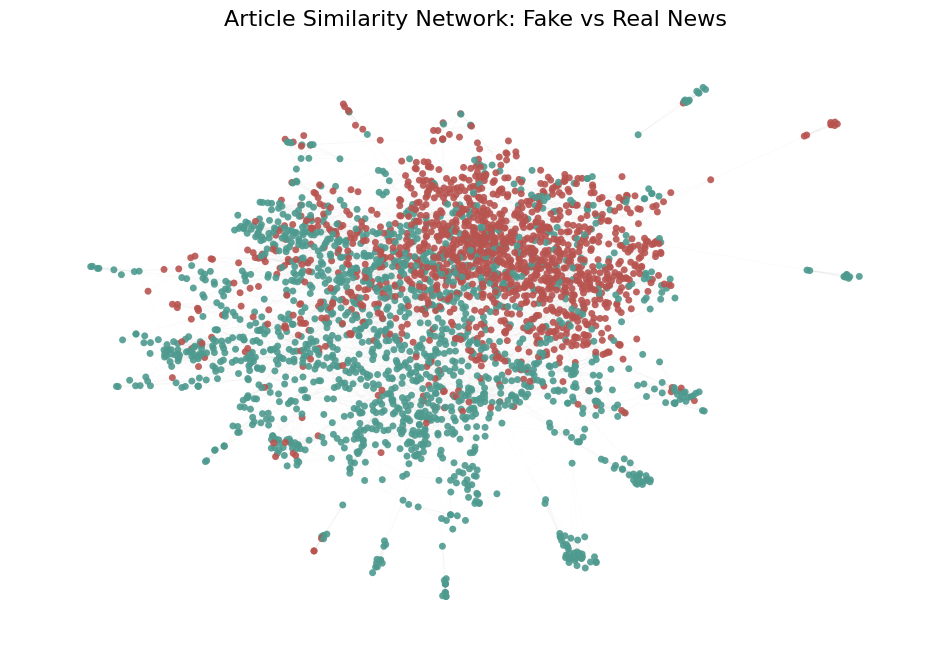

In [12]:
# Force-directed layout: default k lets similar articles cluster together
pos = nx.spring_layout(
    G,
    seed=42,
    weight='weight',   # more similar articles are pulled closer
    iterations=300,    # more iterations so clusters fully settle
)                      # no k= (default is ~1/sqrt(n))

# Muted colors to match the reference
colors = ['#B85450' if ys[n] == 1 else '#4E9A8F' for n in G.nodes()]

plt.figure(figsize=(12, 8))

nx.draw_networkx_edges(
    G, pos,
    alpha=0.04,        # very faint edges
    width=0.3,
    edge_color='gray'
)

nx.draw_networkx_nodes(
    G, pos,
    node_color=colors,
    node_size=25,
    alpha=0.9,
    linewidths=0       # no outline around dots
)

plt.title('Article Similarity Network: Fake vs Real News', fontsize=16)
plt.axis('off')

plt.savefig('similarity_graph.png', dpi=200, bbox_inches='tight')
plt.show()